# 06B — DeepCluster pooled validation analysis

This notebook analyses the completed production run:

`deepcluster_resnet18_pooled_broad_natural_seed42_full_3425705`

The model used a scratch-initialised ResNet-18 backbone and iterative
DeepCluster training with 500 pseudo-label clusters for 50 cycles.

## Analysis policy

- The production run is read-only.
- Development analysis uses the frozen validation split only.
- The held-out test split remains untouched.
- Embeddings are joined using both `crystal_id` and `manifest_order`.
- Clusters are treated as representation diagnostics, not geological proof.
- Cycle 50 remains the predeclared production endpoint.
- The late-cycle pseudo-label classifier decline is reported as an optimisation
  limitation and is not treated by itself as proof of backbone degradation.
- Locality probing is deferred because the cycle-50 train embeddings are not
  present locally.


In [1]:
import hashlib
import itertools
import json
import os
import sys
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

IRP_ROOT = Path(
    os.environ.get(
        "IRP_ROOT",
        "/home/ars223/MSc-GEMS/IRP26",
    )
)

DEV_ROOT = IRP_ROOT / "plagnetplus-dev"

sys.path.insert(
    0,
    str(DEV_ROOT / "src"),
)

from plagnetplus.evaluation import (
    categorical_enrichment_at_k,
    categorical_precision_at_k,
    embedding_qc_summary,
    entropy_effective_rank,
    exact_cosine_neighbours,
    fit_deterministic_pca,
    l2_normalise_rows,
    load_embedding_bundle,
    load_embedding_manifest,
    prepare_cosine_features,
    sampled_mean_pairwise_cosine_similarity,
    sha256_file,
    summarise_pca,
    validate_embedding_manifest_alignment,
)

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

RUN_NAME = (
    "deepcluster_resnet18_pooled_broad_"
    "natural_seed42_full_3425705"
)

RUN_ROOT = (
    IRP_ROOT
    / "runs"
    / "hpc"
    / "deepcluster"
    / RUN_NAME
)

ANALYSIS_ROOT = (
    IRP_ROOT
    / "runs"
    / "analysis"
    / "deepcluster"
    / f"{RUN_NAME}_v1"
)

BENCHMARK_ROOT = (
    IRP_ROOT
    / "data"
    / "processed"
    / "plagnetplus"
    / "ssl_unified_v1"
    / "benchmarks"
    / "pooled_broad_p80_10_10_v1"
)

VALIDATION_MANIFEST = (
    BENCHMARK_ROOT
    / "manifests"
    / "crystals_validation.csv"
)

EMBEDDING_PATH = (
    RUN_ROOT
    / "embeddings"
    / "validation_backbone_embeddings.npz"
)

SIMCLR_ANALYSIS_ROOT = (
    IRP_ROOT
    / "runs"
    / "analysis"
    / "simclr"
    / "simclr_resnet18_pooled_broad_natural_seed42_full_3408095_v1"
)

for subdirectory in (
    "metadata",
    "figures",
    "tables",
    "clustering",
    "clustering/assignments",
    "retrieval",
):
    (ANALYSIS_ROOT / subdirectory).mkdir(
        parents=True,
        exist_ok=True,
    )

for required in (
    RUN_ROOT / "run_summary.json",
    RUN_ROOT / "metadata" / "run_record.json",
    RUN_ROOT / "metadata" / "benchmark_provenance.json",
    RUN_ROOT / "training_history.csv",
    EMBEDDING_PATH,
    VALIDATION_MANIFEST,
    SIMCLR_ANALYSIS_ROOT / "clustering" / "clustering_runs.csv",
    SIMCLR_ANALYSIS_ROOT / "clustering" / "silhouette_sample_v1.npz",
):
    assert required.is_file(), required

def json_ready(value):
    if isinstance(value, dict):
        return {
            str(key): json_ready(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [
            json_ready(item)
            for item in value
        ]

    if isinstance(value, np.ndarray):
        return value.tolist()

    if isinstance(value, np.generic):
        return value.item()

    if isinstance(value, Path):
        return str(value)

    if pd.isna(value) if not isinstance(value, (dict, list, tuple)) else False:
        return None

    return value

def write_json(path, payload):
    path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    path.write_text(
        json.dumps(
            json_ready(payload),
            indent=2,
            sort_keys=True,
        )
        + "\n",
        encoding="utf-8",
    )

def extract_enrichment(summary):
    preferred = (
        "mean_enrichment",
        "enrichment_at_k",
        "enrichment",
    )

    for key in preferred:
        value = summary.get(key)

        if isinstance(value, (int, float, np.number)):
            return float(value)

    for key, value in summary.items():
        if (
            "enrichment" in str(key).lower()
            and isinstance(value, (int, float, np.number))
        ):
            return float(value)

    raise KeyError(
        f"No enrichment metric found in keys: {sorted(summary)}"
    )

print("Run root:", RUN_ROOT)
print("Analysis root:", ANALYSIS_ROOT)
print("Validation manifest:", VALIDATION_MANIFEST)
print("NOTEBOOK INPUT PREFLIGHT: PASS")


Run root: /home/ars223/MSc-GEMS/IRP26/runs/hpc/deepcluster/deepcluster_resnet18_pooled_broad_natural_seed42_full_3425705
Analysis root: /home/ars223/MSc-GEMS/IRP26/runs/analysis/deepcluster/deepcluster_resnet18_pooled_broad_natural_seed42_full_3425705_v1
Validation manifest: /home/ars223/MSc-GEMS/IRP26/data/processed/plagnetplus/ssl_unified_v1/benchmarks/pooled_broad_p80_10_10_v1/manifests/crystals_validation.csv
NOTEBOOK INPUT PREFLIGHT: PASS


## 1. Production provenance and training behaviour

The production engineering checks are separated from scientific interpretation.
A successful 50-cycle run does not imply that the final pseudo-label classifier
was optimally fitted.


,Field,Value
0,Run name,deepcluster_resnet18_pooled_broad_natural_seed...
1,Status,PASS
2,Method,deepcluster
3,Backbone,resnet18
4,Initialisation,scratch
5,Feature dimension,512
6,Production clusters,500
7,Completed cycles,50
8,Training rows,101682
9,Validation embedding shape,"(14919, 512)"


,Metric,Value
0,cycles_completed,50
1,all_clusters_occupied_every_cycle,True
2,minimum_normalised_cluster_entropy,0.996542
3,maximum_largest_cluster_fraction,0.003757
4,best_pseudo_label_accuracy,0.650971
5,best_pseudo_label_accuracy_cycle,39
6,minimum_pseudo_label_loss,1.286432
7,minimum_pseudo_label_loss_cycle,31
8,final_pseudo_label_accuracy,0.297663
9,final_pseudo_label_loss,4.186431


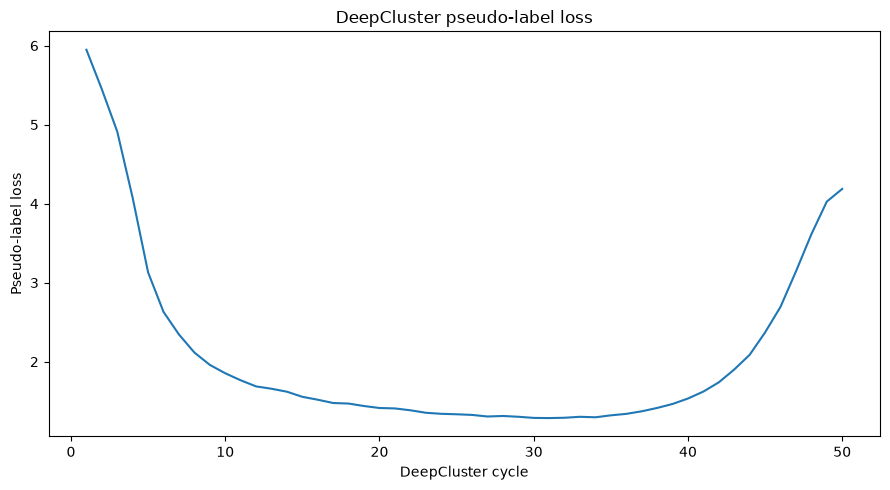

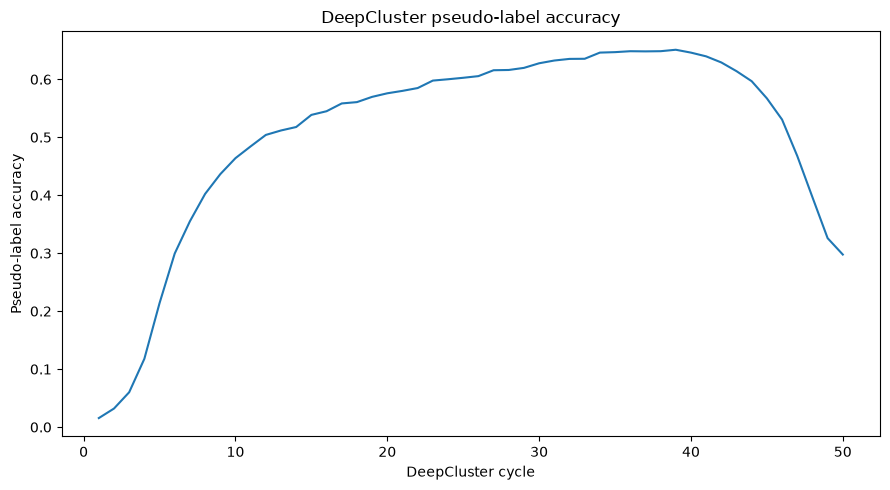

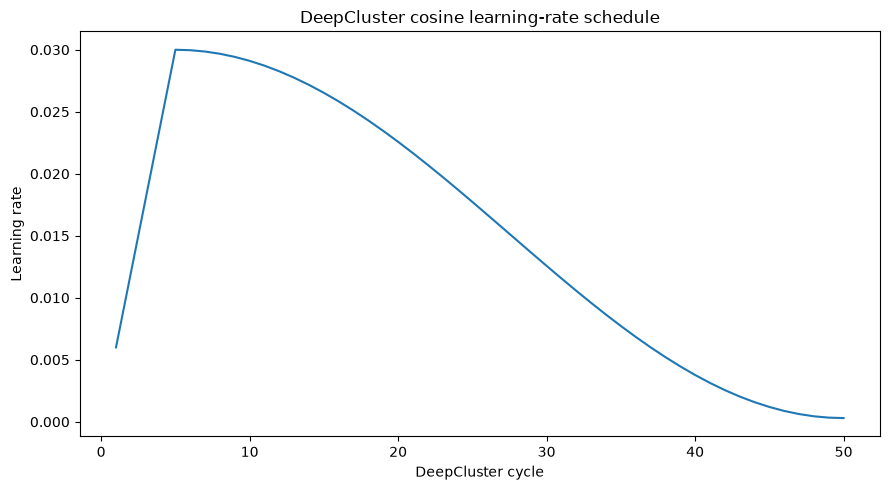

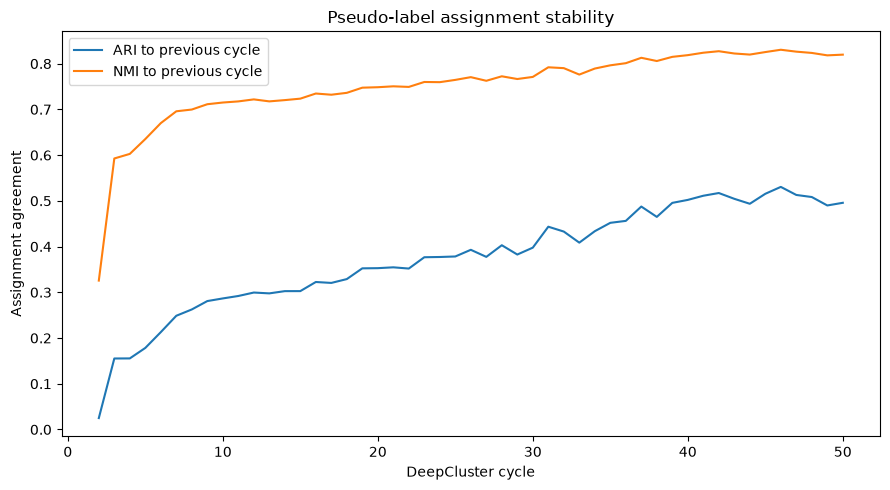

RUN AND TRAINING ANALYSIS: PASS


In [2]:
run_summary = json.loads(
    (RUN_ROOT / "run_summary.json").read_text(
        encoding="utf-8",
    )
)

run_record = json.loads(
    (
        RUN_ROOT
        / "metadata"
        / "run_record.json"
    ).read_text(
        encoding="utf-8",
    )
)

benchmark_provenance = json.loads(
    (
        RUN_ROOT
        / "metadata"
        / "benchmark_provenance.json"
    ).read_text(
        encoding="utf-8",
    )
)

history = pd.read_csv(
    RUN_ROOT / "training_history.csv"
)

assert run_summary["status"] == "PASS"
assert run_summary["cycles_completed"] == 50
assert run_summary["test_split_accessed"] is False
assert run_summary["test_images_accessed"] is False
assert run_summary["validation_embedding_rows"] == 14919
assert run_summary["validation_embedding_dimension"] == 512
assert len(history) == 50
assert history["cycle"].tolist() == list(range(1, 51))
assert history["occupied_clusters"].eq(500).all()
assert np.isfinite(history["pseudo_label_loss"]).all()
assert np.isfinite(history["pseudo_label_accuracy"]).all()

recorded_seconds = float(
    history[
        [
            "feature_seconds",
            "pca_seconds",
            "kmeans_seconds",
            "training_seconds",
        ]
    ].sum().sum()
)

scheduler_gpu_hours = (
    3 * 3600
    + 16 * 60
    + 37
) / 3600.0

best_accuracy_row = history.loc[
    history["pseudo_label_accuracy"].idxmax()
]

lowest_loss_row = history.loc[
    history["pseudo_label_loss"].idxmin()
]

training_summary = {
    "cycles_completed": 50,
    "all_clusters_occupied_every_cycle": bool(
        history["occupied_clusters"].eq(500).all()
    ),
    "minimum_normalised_cluster_entropy": float(
        history["normalised_cluster_entropy"].min()
    ),
    "maximum_largest_cluster_fraction": float(
        history["largest_cluster_fraction"].max()
    ),
    "best_pseudo_label_accuracy": float(
        best_accuracy_row["pseudo_label_accuracy"]
    ),
    "best_pseudo_label_accuracy_cycle": int(
        best_accuracy_row["cycle"]
    ),
    "minimum_pseudo_label_loss": float(
        lowest_loss_row["pseudo_label_loss"]
    ),
    "minimum_pseudo_label_loss_cycle": int(
        lowest_loss_row["cycle"]
    ),
    "final_pseudo_label_accuracy": float(
        history.iloc[-1]["pseudo_label_accuracy"]
    ),
    "final_pseudo_label_loss": float(
        history.iloc[-1]["pseudo_label_loss"]
    ),
    "final_learning_rate": float(
        history.iloc[-1]["learning_rate"]
    ),
    "final_assignment_ari_previous": float(
        history.iloc[-1]["assignment_ari_previous"]
    ),
    "final_assignment_nmi_previous": float(
        history.iloc[-1]["assignment_nmi_previous"]
    ),
    "final_pca_retained_variance": float(
        history.iloc[-1]["pca_retained_variance"]
    ),
    "recorded_pipeline_hours": recorded_seconds / 3600.0,
    "scheduler_gpu_hours": scheduler_gpu_hours,
}

write_json(
    ANALYSIS_ROOT
    / "metadata"
    / "training_history_summary.json",
    training_summary,
)

provenance = pd.DataFrame(
    [
        ("Run name", run_summary["run_name"]),
        ("Status", run_summary["status"]),
        ("Method", run_record["model"]["method"]),
        ("Backbone", run_record["model"]["backbone"]),
        ("Initialisation", run_record["model"]["initialization"]),
        ("Feature dimension", run_record["model"]["feature_dimension"]),
        ("Production clusters", run_record["model"]["cluster_count"]),
        ("Completed cycles", run_summary["cycles_completed"]),
        ("Training rows", run_summary["training_rows"]),
        (
            "Validation embedding shape",
            (
                run_summary["validation_embedding_rows"],
                run_summary["validation_embedding_dimension"],
            ),
        ),
        (
            "Embedding SHA-256",
            run_summary["validation_embeddings"]["sha256"],
        ),
        (
            "Checkpoint SHA-256",
            run_summary["final_checkpoint"]["sha256"],
        ),
        (
            "Benchmark fingerprint",
            run_summary["benchmark_fingerprint"],
        ),
        (
            "Scheduler GPU hours",
            scheduler_gpu_hours,
        ),
        (
            "Test split accessed",
            run_summary["test_split_accessed"],
        ),
    ],
    columns=["Field", "Value"],
)

display(provenance)
display(
    pd.DataFrame(
        training_summary.items(),
        columns=["Metric", "Value"],
    )
)

plt.figure(figsize=(9, 5))
plt.plot(
    history["cycle"],
    history["pseudo_label_loss"],
)
plt.xlabel("DeepCluster cycle")
plt.ylabel("Pseudo-label loss")
plt.title("DeepCluster pseudo-label loss")
plt.tight_layout()
plt.savefig(
    ANALYSIS_ROOT
    / "figures"
    / "pseudo_label_loss.png",
    dpi=160,
)
plt.show()
plt.close()

plt.figure(figsize=(9, 5))
plt.plot(
    history["cycle"],
    history["pseudo_label_accuracy"],
)
plt.xlabel("DeepCluster cycle")
plt.ylabel("Pseudo-label accuracy")
plt.title("DeepCluster pseudo-label accuracy")
plt.tight_layout()
plt.savefig(
    ANALYSIS_ROOT
    / "figures"
    / "pseudo_label_accuracy.png",
    dpi=160,
)
plt.show()
plt.close()

plt.figure(figsize=(9, 5))
plt.plot(
    history["cycle"],
    history["learning_rate"],
)
plt.xlabel("DeepCluster cycle")
plt.ylabel("Learning rate")
plt.title("DeepCluster cosine learning-rate schedule")
plt.tight_layout()
plt.savefig(
    ANALYSIS_ROOT
    / "figures"
    / "learning_rate.png",
    dpi=160,
)
plt.show()
plt.close()

plt.figure(figsize=(9, 5))
plt.plot(
    history["cycle"],
    history["assignment_ari_previous"],
    label="ARI to previous cycle",
)
plt.plot(
    history["cycle"],
    history["assignment_nmi_previous"],
    label="NMI to previous cycle",
)
plt.xlabel("DeepCluster cycle")
plt.ylabel("Assignment agreement")
plt.title("Pseudo-label assignment stability")
plt.legend()
plt.tight_layout()
plt.savefig(
    ANALYSIS_ROOT
    / "figures"
    / "assignment_stability.png",
    dpi=160,
)
plt.show()
plt.close()

print("RUN AND TRAINING ANALYSIS: PASS")


## 2. Embedding integrity and dimensionality

The cycle-50 backbone representation is checked for exact manifest alignment,
finite values, anisotropy and effective dimensionality. PCA is fitted on the
validation embeddings only, following the frozen development contract.


,Metric,Value
0,Embedding rows,14919.000000
1,Feature dimension,512.000000
2,Effective rank,29.348666
3,Normalised effective rank,0.057322
4,Mean pairwise cosine,0.262644
5,PCA components retained,50.000000
6,Variance retained by PCA50,0.954686


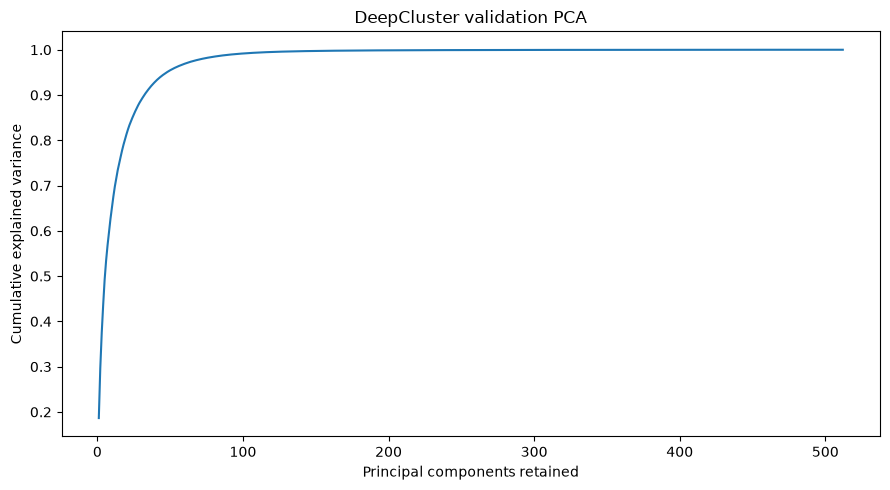

EMBEDDING INTEGRITY AND PCA: PASS


In [3]:
bundle = load_embedding_bundle(
    EMBEDDING_PATH,
    expected_feature_dimension=512,
)

manifest = load_embedding_manifest(
    VALIDATION_MANIFEST,
)

alignment = validate_embedding_manifest_alignment(
    bundle,
    manifest,
)

alignment_boolean_values = [
    bool(value)
    for value in alignment.values()
    if isinstance(value, (bool, np.bool_))
]

if not alignment_boolean_values:
    nested_checks = alignment.get("checks", {})

    alignment_boolean_values = [
        bool(value)
        for value in nested_checks.values()
        if isinstance(value, (bool, np.bool_))
    ]

assert alignment_boolean_values, alignment
assert all(alignment_boolean_values), alignment

embedding_summary, dimension_stats = embedding_qc_summary(
    bundle,
    pair_count=100000,
    pair_seed=42,
)

effective_rank, normalised_effective_rank = (
    entropy_effective_rank(
        bundle.features,
    )
)

mean_pairwise_cosine = (
    sampled_mean_pairwise_cosine_similarity(
        bundle.features,
        pair_count=100000,
        seed=42,
    )
)

dimension_stats.to_csv(
    ANALYSIS_ROOT
    / "metadata"
    / "embedding_dimension_statistics.csv",
    index=False,
)

embedding_integrity = {
    "schema_version": "plagnetplus_embedding_integrity_v1",
    "status": "PASS",
    "model_id": RUN_NAME,
    "split": "validation",
    "inputs": {
        "embedding": str(EMBEDDING_PATH),
        "embedding_sha256": sha256_file(
            EMBEDDING_PATH,
        ),
        "manifest": str(VALIDATION_MANIFEST),
        "rows": int(bundle.features.shape[0]),
        "feature_dimension": int(
            bundle.features.shape[1]
        ),
    },
    "alignment": alignment,
    "representation_health": embedding_summary,
    "derived_metrics": {
        "entropy_effective_rank": float(
            effective_rank
        ),
        "normalised_entropy_effective_rank": float(
            normalised_effective_rank
        ),
        "mean_pairwise_cosine_similarity": float(
            mean_pairwise_cosine
        ),
    },
    "checks": {
        "all_features_finite": bool(
            np.isfinite(bundle.features).all()
        ),
        "test_split_accessed": False,
    },
}

write_json(
    ANALYSIS_ROOT
    / "metadata"
    / "embedding_integrity_summary.json",
    embedding_integrity,
)

pca_result = fit_deterministic_pca(
    bundle.features,
    retained_components=50,
)

pca_summary = summarise_pca(
    pca_result,
)

np.savez_compressed(
    ANALYSIS_ROOT
    / "embeddings_validation_pca_50.npz",
    coordinates=pca_result.coordinates.astype(
        np.float32
    ),
    components=pca_result.components.astype(
        np.float32
    ),
    mean=pca_result.mean.astype(
        np.float32
    ),
    eigenvalues=pca_result.eigenvalues.astype(
        np.float32
    ),
    explained_variance_ratio=(
        pca_result.explained_variance_ratio.astype(
            np.float32
        )
    ),
)

pca_table = pd.DataFrame(
    {
        "component": np.arange(
            1,
            len(
                pca_result.explained_variance_ratio
            )
            + 1,
        ),
        "explained_variance_ratio": (
            pca_result.explained_variance_ratio
        ),
        "cumulative_explained_variance": (
            pca_result.cumulative_explained_variance
        ),
    }
)

pca_table.to_csv(
    ANALYSIS_ROOT
    / "tables"
    / "pca_explained_variance.csv",
    index=False,
)

write_json(
    ANALYSIS_ROOT
    / "metadata"
    / "pca_summary.json",
    pca_summary,
)

display(
    pd.DataFrame(
        {
            "Metric": [
                "Embedding rows",
                "Feature dimension",
                "Effective rank",
                "Normalised effective rank",
                "Mean pairwise cosine",
                "PCA components retained",
                "Variance retained by PCA50",
            ],
            "Value": [
                bundle.features.shape[0],
                bundle.features.shape[1],
                effective_rank,
                normalised_effective_rank,
                mean_pairwise_cosine,
                pca_result.retained_components,
                pca_summary[
                    "variance_retained_by_selected_components"
                ],
            ],
        }
    )
)

plt.figure(figsize=(9, 5))
plt.plot(
    pca_table["component"],
    pca_table["cumulative_explained_variance"],
)
plt.xlabel("Principal components retained")
plt.ylabel("Cumulative explained variance")
plt.title("DeepCluster validation PCA")
plt.tight_layout()
plt.savefig(
    ANALYSIS_ROOT
    / "figures"
    / "pca_cumulative_variance.png",
    dpi=160,
)
plt.show()
plt.close()

print("EMBEDDING INTEGRITY AND PCA: PASS")


## 3. Frozen validation clustering

PCA50 coordinates are row-normalised before k-means. The exact cluster counts,
seeds and silhouette sample used for the completed SimCLR baseline are reused
to preserve model comparability.


,number_of_clusters,median_silhouette,minimum_silhouette,maximum_silhouette,median_inertia,median_largest_cluster_fraction,median_stability_ari,minimum_stability_ari,maximum_stability_ari
0,5,0.17259,0.16518,0.17943,9559.86328,0.30247,0.69337,0.69110,1.00000
1,10,0.16799,0.16543,0.17834,7728.14429,0.12695,0.73210,0.51391,0.99813
2,20,0.17060,0.15648,0.17537,6130.97290,0.07423,0.71252,0.61334,0.88259
3,30,0.16859,0.15961,0.17425,5305.23315,0.05550,0.64577,0.53421,0.75587
4,50,0.16614,0.15786,0.17033,4360.08545,0.04119,0.62455,0.55511,0.75353


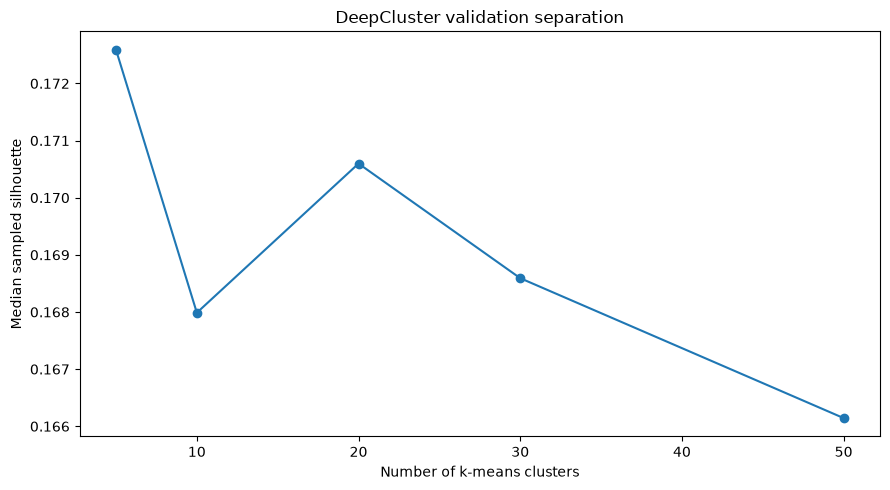

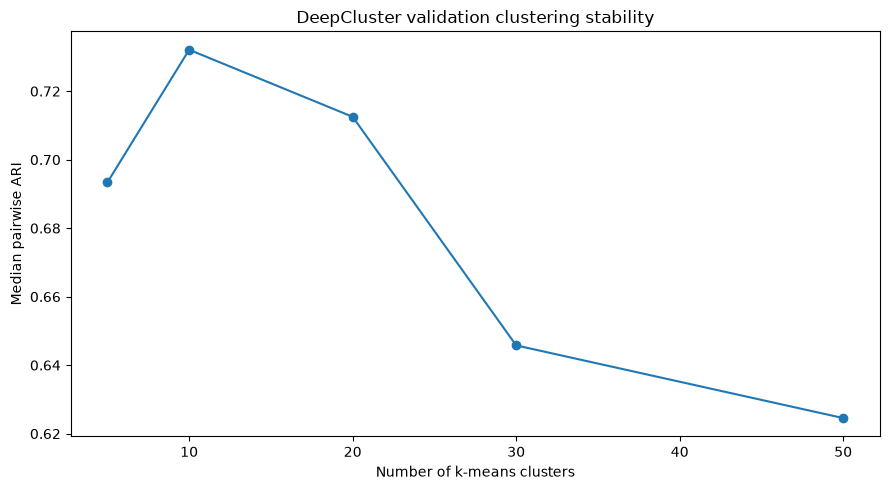

FROZEN VALIDATION CLUSTERING: PASS


In [4]:
simclr_clustering_runs = pd.read_csv(
    SIMCLR_ANALYSIS_ROOT
    / "clustering"
    / "clustering_runs.csv"
)

k_column = next(
    column
    for column in (
        "number_of_clusters",
        "cluster_count",
        "k",
    )
    if column in simclr_clustering_runs.columns
)

seed_column = next(
    column
    for column in (
        "seed",
        "random_seed",
    )
    if column in simclr_clustering_runs.columns
)

K_VALUES = sorted(
    int(value)
    for value in simclr_clustering_runs[
        k_column
    ].unique()
)

SEEDS = sorted(
    int(value)
    for value in simclr_clustering_runs[
        seed_column
    ].unique()
)

assert K_VALUES == [5, 10, 20, 30, 50]
assert len(SEEDS) == 10

with np.load(
    SIMCLR_ANALYSIS_ROOT
    / "clustering"
    / "silhouette_sample_v1.npz",
    allow_pickle=False,
) as sample_bundle:
    sample_key = sample_bundle.files[0]
    silhouette_indices = np.asarray(
        sample_bundle[sample_key],
        dtype=np.int64,
    )

assert silhouette_indices.ndim == 1
assert silhouette_indices.min() >= 0
assert silhouette_indices.max() < len(manifest)

cluster_features = l2_normalise_rows(
    pca_result.coordinates,
)

clustering_rows = []
stability_rows = []
labels_by_k = {}

for number_of_clusters in K_VALUES:
    labels_by_seed = []

    for seed in SEEDS:
        estimator = KMeans(
            n_clusters=number_of_clusters,
            init="k-means++",
            n_init=1,
            max_iter=300,
            tol=1e-4,
            random_state=seed,
            algorithm="lloyd",
        )

        labels = estimator.fit_predict(
            cluster_features,
        )

        labels_by_seed.append(labels)

        sampled_silhouette = silhouette_score(
            cluster_features[silhouette_indices],
            labels[silhouette_indices],
            metric="euclidean",
        )

        counts = np.bincount(
            labels,
            minlength=number_of_clusters,
        )

        clustering_rows.append(
            {
                "model_id": RUN_NAME,
                "split": "validation",
                "number_of_clusters": (
                    number_of_clusters
                ),
                "seed": seed,
                "silhouette": float(
                    sampled_silhouette
                ),
                "inertia": float(
                    estimator.inertia_
                ),
                "iterations": int(
                    estimator.n_iter_
                ),
                "occupied_clusters": int(
                    np.count_nonzero(counts)
                ),
                "minimum_cluster_size": int(
                    counts.min()
                ),
                "median_cluster_size": float(
                    np.median(counts)
                ),
                "maximum_cluster_size": int(
                    counts.max()
                ),
                "largest_cluster_fraction": float(
                    counts.max() / counts.sum()
                ),
            }
        )

        if seed == SEEDS[0]:
            np.savez_compressed(
                ANALYSIS_ROOT
                / "clustering"
                / "assignments"
                / (
                    "validation_kmeans_"
                    f"k{number_of_clusters:04d}.npz"
                ),
                labels=labels.astype(
                    np.int32
                ),
                crystal_ids=bundle.crystal_ids,
                manifest_orders=(
                    bundle.manifest_orders
                ),
                seed=np.asarray(seed),
                number_of_clusters=np.asarray(
                    number_of_clusters
                ),
            )

    labels_by_k[number_of_clusters] = (
        np.stack(
            labels_by_seed,
            axis=0,
        )
    )

    for left_index, right_index in (
        itertools.combinations(
            range(len(SEEDS)),
            2,
        )
    ):
        stability_rows.append(
            {
                "number_of_clusters": (
                    number_of_clusters
                ),
                "seed_left": SEEDS[left_index],
                "seed_right": SEEDS[right_index],
                "adjusted_rand_index": float(
                    adjusted_rand_score(
                        labels_by_seed[left_index],
                        labels_by_seed[right_index],
                    )
                ),
            }
        )

clustering_runs = pd.DataFrame(
    clustering_rows
)

stability_pairs = pd.DataFrame(
    stability_rows
)

clustering_by_k = (
    clustering_runs.groupby(
        "number_of_clusters",
        as_index=False,
    )
    .agg(
        median_silhouette=(
            "silhouette",
            "median",
        ),
        minimum_silhouette=(
            "silhouette",
            "min",
        ),
        maximum_silhouette=(
            "silhouette",
            "max",
        ),
        median_inertia=(
            "inertia",
            "median",
        ),
        median_largest_cluster_fraction=(
            "largest_cluster_fraction",
            "median",
        ),
    )
)

stability_by_k = (
    stability_pairs.groupby(
        "number_of_clusters",
        as_index=False,
    )
    .agg(
        median_stability_ari=(
            "adjusted_rand_index",
            "median",
        ),
        minimum_stability_ari=(
            "adjusted_rand_index",
            "min",
        ),
        maximum_stability_ari=(
            "adjusted_rand_index",
            "max",
        ),
    )
)

clustering_by_k = clustering_by_k.merge(
    stability_by_k,
    on="number_of_clusters",
    how="inner",
    validate="one_to_one",
)

clustering_runs.to_csv(
    ANALYSIS_ROOT
    / "clustering"
    / "clustering_runs.csv",
    index=False,
)

stability_pairs.to_csv(
    ANALYSIS_ROOT
    / "clustering"
    / "clustering_stability_pairs.csv",
    index=False,
)

clustering_by_k.to_csv(
    ANALYSIS_ROOT
    / "clustering"
    / "clustering_summary_by_k.csv",
    index=False,
)

median_silhouette = float(
    clustering_by_k[
        "median_silhouette"
    ].median()
)

median_stability_ari = float(
    clustering_by_k[
        "median_stability_ari"
    ].median()
)

clustering_summary = {
    "schema_version": "plagnetplus_clustering_summary_v1",
    "status": "PASS",
    "model_id": RUN_NAME,
    "split": "validation",
    "input": {
        "representation": "validation_pca50_row_l2",
        "rows": int(cluster_features.shape[0]),
        "dimensions": int(cluster_features.shape[1]),
        "cluster_counts": K_VALUES,
        "seeds": SEEDS,
        "silhouette_sample_rows": int(
            len(silhouette_indices)
        ),
    },
    "headline_metrics": {
        "median_silhouette_across_k": (
            median_silhouette
        ),
        "median_stability_ari_across_k": (
            median_stability_ari
        ),
    },
    "checks": {
        "all_runs_occupied_all_clusters": bool(
            (
                clustering_runs[
                    "occupied_clusters"
                ]
                == clustering_runs[
                    "number_of_clusters"
                ]
            ).all()
        ),
        "all_metrics_finite": bool(
            np.isfinite(
                clustering_runs[
                    [
                        "silhouette",
                        "inertia",
                    ]
                ].to_numpy()
            ).all()
        ),
        "test_split_accessed": False,
    },
}

assert clustering_summary[
    "checks"
]["all_runs_occupied_all_clusters"]

write_json(
    ANALYSIS_ROOT
    / "clustering"
    / "clustering_summary.json",
    clustering_summary,
)

display(
    clustering_by_k.round(5)
)

plt.figure(figsize=(9, 5))
plt.plot(
    clustering_by_k["number_of_clusters"],
    clustering_by_k["median_silhouette"],
    marker="o",
)
plt.xlabel("Number of k-means clusters")
plt.ylabel("Median sampled silhouette")
plt.title("DeepCluster validation separation")
plt.tight_layout()
plt.savefig(
    ANALYSIS_ROOT
    / "figures"
    / "clustering_silhouette_by_k.png",
    dpi=160,
)
plt.show()
plt.close()

plt.figure(figsize=(9, 5))
plt.plot(
    clustering_by_k["number_of_clusters"],
    clustering_by_k["median_stability_ari"],
    marker="o",
)
plt.xlabel("Number of k-means clusters")
plt.ylabel("Median pairwise ARI")
plt.title("DeepCluster validation clustering stability")
plt.tight_layout()
plt.savefig(
    ANALYSIS_ROOT
    / "figures"
    / "clustering_stability_by_k.png",
    dpi=160,
)
plt.show()
plt.close()

print("FROZEN VALIDATION CLUSTERING: PASS")


## 4. Retrieval and source-image confounding

Raw and mean-centred cosine representations are evaluated separately.

The automatic FCT diagnostic excludes neighbours from the same physical
sample. It is a pipeline diagnostic unrelated to geological signifigance. Same-source-image enrichment is retained as the acquisition
confounder metric.


In [5]:
raw_features = prepare_cosine_features(
    bundle.features,
    centre=False,
)

centred_features = prepare_cosine_features(
    bundle.features,
    centre=True,
)

physical_sample_codes = pd.factorize(
    manifest["physical_sample_id"].astype(str),
    sort=True,
)[0]

locality_labels = (
    manifest["locality"]
    .astype(str)
    .to_numpy()
)

source_image_labels = (
    manifest["source_image_sha256"]
    .astype(str)
    .to_numpy()
)

fct_query_mask = (
    locality_labels == "FCT"
)

assert fct_query_mask.any()

raw_indices, raw_scores = (
    exact_cosine_neighbours(
        raw_features,
        neighbour_count=10,
        chunk_size=256,
    )
)

centred_indices, centred_scores = (
    exact_cosine_neighbours(
        centred_features,
        neighbour_count=10,
        chunk_size=256,
    )
)

raw_cross_sample_indices, raw_cross_sample_scores = (
    exact_cosine_neighbours(
        raw_features,
        neighbour_count=10,
        exclusion_codes=physical_sample_codes,
        chunk_size=256,
    )
)

(
    centred_cross_sample_indices,
    centred_cross_sample_scores,
) = exact_cosine_neighbours(
    centred_features,
    neighbour_count=10,
    exclusion_codes=physical_sample_codes,
    chunk_size=256,
)

np.savez_compressed(
    ANALYSIS_ROOT
    / "retrieval"
    / "raw_cosine_neighbours_v1.npz",
    neighbour_indices=raw_indices.astype(
        np.int32
    ),
    cosine_scores=raw_scores.astype(
        np.float32
    ),
    crystal_ids=bundle.crystal_ids,
    manifest_orders=bundle.manifest_orders,
)

np.savez_compressed(
    ANALYSIS_ROOT
    / "retrieval"
    / "centred_cosine_neighbours_v1.npz",
    neighbour_indices=centred_indices.astype(
        np.int32
    ),
    cosine_scores=centred_scores.astype(
        np.float32
    ),
    crystal_ids=bundle.crystal_ids,
    manifest_orders=bundle.manifest_orders,
)

np.savez_compressed(
    ANALYSIS_ROOT
    / "retrieval"
    / "raw_cross_sample_cosine_neighbours_v1.npz",
    neighbour_indices=(
        raw_cross_sample_indices.astype(
            np.int32
        )
    ),
    cosine_scores=(
        raw_cross_sample_scores.astype(
            np.float32
        )
    ),
    crystal_ids=bundle.crystal_ids,
    manifest_orders=bundle.manifest_orders,
)

np.savez_compressed(
    ANALYSIS_ROOT
    / "retrieval"
    / "centred_cross_sample_cosine_neighbours_v1.npz",
    neighbour_indices=(
        centred_cross_sample_indices.astype(
            np.int32
        )
    ),
    cosine_scores=(
        centred_cross_sample_scores.astype(
            np.float32
        )
    ),
    crystal_ids=bundle.crystal_ids,
    manifest_orders=bundle.manifest_orders,
)

automatic_fct_raw_p10 = (
    categorical_precision_at_k(
        raw_cross_sample_indices,
        locality_labels,
        k=10,
        query_mask=fct_query_mask,
    )
)

automatic_fct_centred_p10 = (
    categorical_precision_at_k(
        centred_cross_sample_indices,
        locality_labels,
        k=10,
        query_mask=fct_query_mask,
    )
)

source_raw = categorical_enrichment_at_k(
    raw_indices,
    source_image_labels,
    k=10,
)

source_centred = categorical_enrichment_at_k(
    centred_indices,
    source_image_labels,
    k=10,
)

source_raw_enrichment = extract_enrichment(
    source_raw
)

source_centred_enrichment = extract_enrichment(
    source_centred
)

retrieval_metrics = pd.DataFrame(
    [
        {
            "representation": "raw_cosine",
            "automatic_fct_cross_sample_p10": (
                automatic_fct_raw_p10
            ),
            "source_image_enrichment_at10": (
                source_raw_enrichment
            ),
        },
        {
            "representation": "centred_cosine",
            "automatic_fct_cross_sample_p10": (
                automatic_fct_centred_p10
            ),
            "source_image_enrichment_at10": (
                source_centred_enrichment
            ),
        },
    ]
)

retrieval_metrics.to_csv(
    ANALYSIS_ROOT
    / "retrieval"
    / "retrieval_metrics_by_representation_and_k.csv",
    index=False,
)

retrieval_summary = {
    "schema_version": "plagnetplus_retrieval_summary_v1",
    "status": "PASS",
    "model_id": RUN_NAME,
    "split": "validation",
    "input": {
        "rows": int(len(manifest)),
        "neighbours": 10,
        "cross_sample_exclusion": (
            "physical_sample_id"
        ),
        "automatic_diagnostic_locality": "FCT",
        "automatic_diagnostic_query_rows": int(
            fct_query_mask.sum()
        ),
    },
    "headline_automatic_diagnostics": {
        "automatic_fct_cross_sample_precision_at_10_raw": (
            float(automatic_fct_raw_p10)
        ),
        "automatic_fct_cross_sample_precision_at_10_centred": (
            float(automatic_fct_centred_p10)
        ),
        "source_image_enrichment_at_10_raw": (
            source_raw_enrichment
        ),
        "source_image_enrichment_at_10_centred": (
            source_centred_enrichment
        ),
    },
    "source_image_enrichment_details": {
        "raw": source_raw,
        "centred": source_centred,
    },
    "checks": {
        "raw_neighbours_finite": bool(
            np.isfinite(raw_scores).all()
        ),
        "centred_neighbours_finite": bool(
            np.isfinite(centred_scores).all()
        ),
        "test_split_accessed": False,
    },
}

write_json(
    ANALYSIS_ROOT
    / "retrieval"
    / "retrieval_summary.json",
    retrieval_summary,
)

display(
    retrieval_metrics.round(6)
)

print("VALIDATION RETRIEVAL: PASS")


,representation,automatic_fct_cross_sample_p10,source_image_enrichment_at10
0,raw_cosine,0.109637,4.182908
1,centred_cosine,0.113354,4.195067


VALIDATION RETRIEVAL: PASS


## 5. Final model summary

The final summary separates completed comparison metrics from deferred metrics.
The absence of cycle-50 train embeddings means the frozen train-to-validation
locality probe is not manufactured from an invalid validation-only substitute.


In [ ]:
interpretation = [
    (
        "The production run completed successfully with all 500 pseudo-label "
        "clusters occupied in every cycle."
    ),
    (
        "Cycle 50 retained balanced clusters and moderate assignment "
        "agreement with cycle 49, so the run did not exhibit cluster collapse."
    ),
    (
        "The late decline in pseudo-label classifier accuracy coincides with "
        "the learning rate approaching its floor while the classifier was "
        "still reset each cycle. This is an optimisation diagnostic rather "
        "than direct evidence that the backbone representation collapsed."
    ),
    (
        "Validation clustering and retrieval metrics quantify representation "
        "structure but do not by themselves demonstrate geological meaning."
    ),
    (
        "Same-source-image enrichment is treated as an acquisition confounder "
        "this should be considered regarding geological interpretation."
    ),
    (
        "The locality train-to-validation probe remains deferred until "
        "cycle-50 training embeddings are deliberately exported."
    ),
]

comparison_metrics = {
    "median_silhouette": median_silhouette,
    "median_stability_ari": (
        median_stability_ari
    ),
    "automatic_fct_cross_sample_precision_at_10_raw": (
        float(automatic_fct_raw_p10)
    ),
    "automatic_fct_cross_sample_precision_at_10_centred": (
        float(automatic_fct_centred_p10)
    ),
    "expert_retrieval_precision_at_10": None,
    "locality_macro_f1": None,
    "source_image_enrichment_at_10_raw": (
        source_raw_enrichment
    ),
    "source_image_enrichment_at_10_centred": (
        source_centred_enrichment
    ),
    "validation_effective_rank": float(
        effective_rank
    ),
    "mean_pairwise_cosine_similarity": float(
        mean_pairwise_cosine
    ),
    "gpu_hours": scheduler_gpu_hours,
}

analysis_summary = {
    "schema_version": "plagnetplus_analysis_summary_v1",
    "status": "PASS",
    "generated_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "model_id": RUN_NAME,
    "method": "deepcluster",
    "backbone": "resnet18",
    "initialization": "scratch",
    "seed": 42,
    "sampling": "natural_frequency",
    "benchmark": {
        "benchmark_id": (
            run_record["config"]["benchmark_id"]
        ),
        "fingerprint": (
            run_summary["benchmark_fingerprint"]
        ),
        "training_rows": (
            run_summary["training_rows"]
        ),
        "validation_rows": (
            run_summary[
                "validation_embedding_rows"
            ]
        ),
        "test_rows": (
            run_record["config"][
                "expected_test_rows"
            ]
        ),
        "test_split_accessed": False,
        "test_images_accessed": False,
    },
    "provenance": {
        "run_root": str(RUN_ROOT),
        "embedding_path": str(
            EMBEDDING_PATH
        ),
        "embedding_sha256": sha256_file(
            EMBEDDING_PATH
        ),
        "checkpoint_sha256": (
            run_summary[
                "final_checkpoint"
            ]["sha256"]
        ),
        "production_cycle": 50,
    },
    "training": training_summary,
    "representation": {
        "embedding_integrity": (
            embedding_integrity
        ),
    },
    "pca": pca_summary,
    "clustering": clustering_summary,
    "retrieval": retrieval_summary,
    "locality_probe": {
        "status": "DEFERRED",
        "reason": (
            "Cycle-50 train embeddings are not "
            "present locally; validation-only fitting "
            "would violate the frozen evaluation contract."
        ),
        "fit_split": "train",
        "evaluation_split": "validation",
        "test_split_accessed": False,
    },
    "expert_retrieval": {
        "status": "PENDING",
        "precision_at_10": None,
    },
    "comparison_metrics": comparison_metrics,
    "interpretation": interpretation,
    "checks": {
        "run_status_pass": (
            run_summary["status"] == "PASS"
        ),
        "cycle_count_complete": (
            run_summary["cycles_completed"] == 50
        ),
        "embedding_alignment_pass": bool(
            alignment_boolean_values
        )
        and all(alignment_boolean_values),
        "clustering_pass": (
            clustering_summary["status"] == "PASS"
        ),
        "retrieval_pass": (
            retrieval_summary["status"] == "PASS"
        ),
        "test_split_untouched": True,
    },
    "artifacts": {
        "analysis_root": str(
            ANALYSIS_ROOT
        ),
        "notebook": str(
            DEV_ROOT
            / "notebooks"
            / "06B_DeepCluster_Pooled_Analysis.ipynb"
        ),
        "training_history_summary": str(
            ANALYSIS_ROOT
            / "metadata"
            / "training_history_summary.json"
        ),
        "embedding_integrity_summary": str(
            ANALYSIS_ROOT
            / "metadata"
            / "embedding_integrity_summary.json"
        ),
        "clustering_summary": str(
            ANALYSIS_ROOT
            / "clustering"
            / "clustering_summary.json"
        ),
        "retrieval_summary": str(
            ANALYSIS_ROOT
            / "retrieval"
            / "retrieval_summary.json"
        ),
    },
}

assert all(
    analysis_summary["checks"].values()
)

summary_path = (
    ANALYSIS_ROOT
    / "analysis_summary.json"
)

write_json(
    summary_path,
    analysis_summary,
)

summary_sha = sha256_file(
    summary_path
)

(
    ANALYSIS_ROOT
    / "analysis_summary.sha256"
).write_text(
    f"{summary_sha}  {summary_path.name}\n",
    encoding="utf-8",
)

execution_summary = {
    "schema_version": "plagnetplus_notebook_execution_v1",
    "status": "PASS",
    "executed_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "notebook": str(
        DEV_ROOT
        / "notebooks"
        / "06B_DeepCluster_Pooled_Analysis.ipynb"
    ),
    "checks": {
        "analysis_summary_written": (
            summary_path.is_file()
        ),
        "test_split_accessed": False,
    },
    "errors": [],
}

write_json(
    ANALYSIS_ROOT
    / "metadata"
    / "notebook_execution_v1.json",
    execution_summary,
)

comparison_table = pd.DataFrame(
    [
        {
            "Model": "DeepCluster ResNet-18",
            "Median silhouette": (
                median_silhouette
            ),
            "Median stability ARI": (
                median_stability_ari
            ),
            "Automatic FCT cross-sample P@10": (
                automatic_fct_raw_p10
            ),
            "Expert texture P@10": None,
            "Locality macro-F1": None,
            "Source-image enrichment@10": (
                source_raw_enrichment
            ),
            "Validation effective rank": (
                effective_rank
            ),
            "GPU hours": scheduler_gpu_hours,
        }
    ]
)

display(
    comparison_table.round(5)
)

print()
print("Analysis summary:", summary_path)
print("Analysis summary SHA-256:", summary_sha)
print()
print("DEEPCLUSTER POOLED ANALYSIS: PASS")


,Model,Median silhouette,Median stability ARI,Automatic FCT cross-sample P@10,Expert texture P@10,Locality macro-F1,Source-image enrichment@10,Validation effective rank,GPU hours
0,DeepCluster ResNet-18,0.16859,0.69337,0.10964,None,None,4.18291,29.34867,3.27694



Analysis summary: /home/ars223/MSc-GEMS/IRP26/runs/analysis/deepcluster/deepcluster_resnet18_pooled_broad_natural_seed42_full_3425705_v1/analysis_summary.json
Analysis summary SHA-256: 79c9a86fbd12b6e14f40be63e557b5899b7d07eab05d1aefaf5198d5e7dccad1

DEEPCLUSTER POOLED ANALYSIS: PASS
